## import library dan lokasi dataset

In [2]:
from pathlib import Path
import pandas as pd

CURRENT_DIR = Path.cwd()
PROJECT_ROOT = (
    CURRENT_DIR.parent
    if CURRENT_DIR.name == "notebooks"
    else CURRENT_DIR
)

# Lokasi dataset.
DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "raw"
    / "online_shoppers_intention.csv"
)

print("Lokasi dataset:", DATA_PATH)
print("File ditemukan:", DATA_PATH.is_file())

Lokasi dataset: c:\Users\elsae\Downloads\ecommerce-purchase-prediction\data\raw\online_shoppers_intention.csv
File ditemukan: True


##  Membaca dataset

In [3]:
df = pd.read_csv(DATA_PATH)

print("Jumlah baris:", df.shape[0])
print("Jumlah kolom:", df.shape[1])

# Menampilkan lima baris pertama.
print("Contoh data:")
df.head()

Jumlah baris: 12330
Jumlah kolom: 18
Contoh data:


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  object 
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType           

In [6]:
# Kolom berisi kode kategori meskipun disimpan sebagai angka.
coded_categorical_columns = [
    "OperatingSystems",
    "Browser",
    "Region",
    "TrafficType",
]

df[coded_categorical_columns].head()

,OperatingSystems,Browser,Region,TrafficType
0,1,1,1,1
1,2,2,1,2
2,4,1,9,3
3,3,2,2,4
4,3,3,1,4


## Pengecekan baris identik

In [ ]:
# Menghitung salinan tambahan setelah kemunculan pertama
duplicate_count = df.duplicated().sum()

print("Jumlah baris:", len(df))
print("Jumlah salinan tambahan:", duplicate_count)

Jumlah baris: 12330
Jumlah salinan tambahan: 125


In [9]:
# Menampilkan semua anggota kelompok baris identik,
# termasuk kemunculan pertamanya.
duplicate_rows = df[df.duplicated(keep=False)]

duplicate_rows.head(10)

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
85,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,1,1,1,3,Returning_Visitor,False,False
132,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,3,2,3,3,Returning_Visitor,False,False
158,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,1,1,1,3,Returning_Visitor,False,False
159,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,3,2,3,3,Returning_Visitor,False,False
178,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,3,2,3,3,Returning_Visitor,False,False
252,0,0.0,0,0.0,2,0.0,0.2,0.2,0.0,0.0,Mar,1,1,1,1,Returning_Visitor,False,False
286,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Mar,2,2,1,1,Returning_Visitor,False,False
293,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Mar,1,1,1,1,Returning_Visitor,True,False
298,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Mar,1,1,8,1,Returning_Visitor,False,False
330,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Mar,3,2,3,1,Returning_Visitor,False,False


In [10]:
df.duplicated().sum()

np.int64(125)

In [11]:
df.duplicated(keep=False)

0        False
1        False
2        False
3        False
4        False
         ...  
12325    False
12326    False
12327    False
12328    False
12329    False
Length: 12330, dtype: bool

Hasil pemeriksaan baris yang identik

Dari 12.330 baris (data), ditemukan 125 salinan tambahan yang memiliki nilai sama persis pada seluruh 18 kolom

Pengulangan ini belum dapat dipastikan sebagai kesalahan pencatatan karena sesi berbeda dapat memiliki karakteristik yang sama. Dataset tidak menyediakan ID sesi untuk melakukan verifikasi lebih lanjut. Pada tahap ini baris identik tidak di hapus

## Pemeriksaan rentang nilai numerik

In [12]:
# Fitur yang secara makna merupakan angka
numerical_columns = [
    "Administrative",
    "Administrative_Duration",
    "Informational",
    "Informational_Duration",
    "ProductRelated",
    "ProductRelated_Duration",
    "BounceRates",
    "ExitRates",
    "PageValues",
    "SpecialDay",
]

# Menampilkan ringkasan nilai setiap fitur numerik
numeric_summary = df[numerical_columns].describe().T

numeric_summary[["min", "50%", "mean", "max"]]

,min,50%,mean,max
Administrative,0.0,1.000000,2.315166,27.000000
Administrative_Duration,0.0,7.500000,80.818611,3398.750000
Informational,0.0,0.000000,0.503569,24.000000
Informational_Duration,0.0,0.000000,34.472398,2549.375000
ProductRelated,0.0,18.000000,31.731468,705.000000
ProductRelated_Duration,0.0,598.936905,1194.746220,63973.522230
BounceRates,0.0,0.003112,0.022191,0.200000
ExitRates,0.0,0.025156,0.043073,0.200000
PageValues,0.0,0.000000,5.889258,361.763742
SpecialDay,0.0,0.000000,0.061427,1.000000


## Memeriksa kategori yang tersedia

In [13]:
# Fitur kategorikal, termasuk kode angka dan boolean
categorical_columns = [
    "Month",
    "OperatingSystems",
    "Browser",
    "Region",
    "TrafficType",
    "VisitorType",
    "Weekend",
]

# Menampilkan kategori yang tersedia pada setiap kolom
for column in categorical_columns:
    print(f"\n{column} — {df[column].nunique()} kategori")
    print(df[column].unique().tolist())


Month — 10 kategori
['Feb', 'Mar', 'May', 'Oct', 'June', 'Jul', 'Aug', 'Nov', 'Sep', 'Dec']

OperatingSystems — 8 kategori
[1, 2, 4, 3, 7, 6, 8, 5]

Browser — 13 kategori
[1, 2, 3, 4, 5, 6, 7, 10, 8, 9, 12, 13, 11]

Region — 9 kategori
[1, 9, 2, 3, 4, 5, 6, 7, 8]

TrafficType — 20 kategori
[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 18, 19, 16, 17, 20]

VisitorType — 3 kategori
['Returning_Visitor', 'New_Visitor', 'Other']

Weekend — 2 kategori
[False, True]


dataset mencakup 10 bulan tanpa Januari dan April, dengan 8 kategori sistem operasi, 13 browser, 9 wilayah, serta 20 jenis trafik. Pengunjung terbagi menjadi `Returning_Visitor`, `New_Visitor`, dan `Other`, sedangkan `Weekend` memiliki nilai `True` dan `False`. Kolom sistem operasi, browser, wilayah, dan jenis trafik akan diperlakukan sebagai fitur kategorikal meskipun nilainya berupa kode angka.

## Memeriksa distribusi target Revenue

In [14]:
# Menghitung jumlah sesi pada setiap kelas.
target_summary = (
    df["Revenue"]
    .value_counts()
    .rename_axis("Revenue")
    .to_frame(name="session_count")
)

# Menghitung persentase setiap kelas.
target_summary["percentage"] = (
    target_summary["session_count"] / len(df) * 100
).round(2)

target_summary

,session_count,percentage
Revenue,,
False,10422,84.53
True,1908,15.47


Distribusi imbalanced karena kelas tidak membeli jauh lebih banyak

## Memisahkan fitur dan target

In [15]:
# Semua kolom selain Revenue menjadi fitur.
X = df.drop(columns=["Revenue"]).copy()

# Revenue menjadi target: False = 0, True = 1.
y = df["Revenue"].astype(int)

print("Ukuran fitur (X):", X.shape)
print("Ukuran target (y):", y.shape)
print("Kelas target:", sorted(y.unique().tolist()))

Ukuran fitur (X): (12330, 17)
Ukuran target (y): (12330,)
Kelas target: [0, 1]


Data berhasil dipisahkan menjadi fitur (`X`) dan target (`y`). `X` berisi 12.330 baris dengan 17 fitur sebagai masukan model, sedangkan `y` berupa satu deret berisi 12.330 label pembelian. Target memiliki dua kelas, yaitu `0` untuk tidak membeli dan `1` untuk membeli. Kolom `Revenue` tidak disertakan dalam `X` karena merupakan jawaban yang akan diprediksi.

## Kelompok untuk pembagian Data

In [16]:
# Fitur yang menjadi dasar pengelompokan.
grouping_features = X.drop(columns=["PageValues"])

# Memberikan nomor kelompok untuk setiap kombinasi fitur.
groups = grouping_features.groupby(
    grouping_features.columns.tolist(),
    sort=False,
    dropna=False,
).ngroup()

print("Jumlah sesi:", len(X))
print("Jumlah kelompok pola fitur:", groups.nunique())

Jumlah sesi: 12330
Jumlah kelompok pola fitur: 12205


## Memisahkan Test Set

In [17]:
from sklearn.model_selection import StratifiedGroupKFold


# Membuat rancangan pembagian menjadi lima bagian.
outer_split = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42,
)

# Mengambil pembagian pertama:
# empat bagian untuk training + validation, satu bagian untuk test.
trainval_idx, test_idx = next(
    outer_split.split(X, y, groups=groups)
)

# Mengambil fitur dan target sesuai posisi baris.
X_trainval = X.iloc[trainval_idx].copy()
y_trainval = y.iloc[trainval_idx].copy()

X_test = X.iloc[test_idx].copy()
y_test = y.iloc[test_idx].copy()

# Menyimpan kelompok pada masing-masing bagian.
groups_trainval = groups.iloc[trainval_idx].copy()
groups_test = groups.iloc[test_idx].copy()

print(
    f"Training + validation: {len(X_trainval)} sesi "
    f"({len(X_trainval) / len(X):.2%})"
)

print(
    f"Test: {len(X_test)} sesi "
    f"({len(X_test) / len(X):.2%})"
)

Training + validation: 9860 sesi (79.97%)
Test: 2470 sesi (20.03%)


In [18]:
# Membagi data training + validation menjadi empat bagian.
inner_split = StratifiedGroupKFold(
    n_splits=4,
    shuffle=True,
    random_state=42,
)

# Mengambil tiga bagian untuk training dan satu untuk validation.
train_idx, val_idx = next(
    inner_split.split(
        X_trainval,
        y_trainval,
        groups=groups_trainval,
    )
)

# Data training.
X_train = X_trainval.iloc[train_idx].copy()
y_train = y_trainval.iloc[train_idx].copy()
groups_train = groups_trainval.iloc[train_idx].copy()

# Data validation.
X_val = X_trainval.iloc[val_idx].copy()
y_val = y_trainval.iloc[val_idx].copy()
groups_val = groups_trainval.iloc[val_idx].copy()

In [19]:
# Merangkum ukuran ketiga bagian.
split_summary = pd.DataFrame(
    {
        "session_count": [
            len(X_train),
            len(X_val),
            len(X_test),
        ]
    },
    index=["Training", "Validation", "Test"],
)

split_summary["percentage"] = (
    split_summary["session_count"] / len(X) * 100
).round(2)

split_summary

,session_count,percentage
Training,7406,60.06
Validation,2454,19.90
Test,2470,20.03


## Pemeriksaan hasil pembagian data

In [20]:
# Menghitung sesi tidak membeli dan membeli.
class_balance = pd.DataFrame(
    {
        "not_purchased": [
            (y_train == 0).sum(),
            (y_val == 0).sum(),
            (y_test == 0).sum(),
        ],
        "purchased": [
            y_train.sum(),
            y_val.sum(),
            y_test.sum(),
        ],
    },
    index=["Training", "Validation", "Test"],
)

# Menghitung persentase pembeli pada setiap bagian.
class_balance["purchase_pct"] = (
    class_balance["purchased"]
    / class_balance.sum(axis=1)
    * 100
).round(2)

class_balance

,not_purchased,purchased,purchase_pct
Training,6223,1183,15.97
Validation,2084,370,15.08
Test,2115,355,14.37


In [21]:
# Mengambil kumpulan nomor kelompok pada setiap bagian.
train_groups = set(groups_train)
val_groups = set(groups_val)
test_groups = set(groups_test)

# Menghitung kelompok yang muncul di dua bagian sekaligus.
group_overlap = pd.Series(
    {
        "Training–Validation": len(train_groups & val_groups),
        "Training–Test": len(train_groups & test_groups),
        "Validation–Test": len(val_groups & test_groups),
    },
    name="shared_groups",
)

group_overlap

Training–Validation    0
Training–Test          0
Validation–Test        0
Name: shared_groups, dtype: int64

## Menyimpan pembagian data

In [22]:
# Membuat daftar baris, kelompok, dan bagian dataset.
split_manifest = pd.DataFrame(
    {
        "row_id": X.index,
        "group_id": groups,
        "split": "",
    },
    index=X.index,
)

# Menandai bagian untuk setiap baris.
split_manifest.loc[X_train.index, "split"] = "train"
split_manifest.loc[X_val.index, "split"] = "validation"
split_manifest.loc[X_test.index, "split"] = "test"

# Menyiapkan folder penyimpanan.
SPLIT_DIR = PROJECT_ROOT / "data" / "splits"
SPLIT_DIR.mkdir(parents=True, exist_ok=True)

# Menyimpan pembagian ke CSV.
SPLIT_PATH = SPLIT_DIR / "split_manifest.csv"
split_manifest.to_csv(SPLIT_PATH, index=False)

print("Pembagian data disimpan di:", SPLIT_PATH)

split_manifest.head()

Pembagian data disimpan di: c:\Users\elsae\Downloads\ecommerce-purchase-prediction\data\splits\split_manifest.csv


,row_id,group_id,split
0,0,0,train
1,1,1,test
2,2,2,train
3,3,3,train
4,4,4,test


# Exploratory Data Analysis

In [23]:
# Membuat salinan data training untuk analisis.
eda_train = X_train.copy()

# Menggabungkan kembali target untuk kebutuhan analisis.
eda_train["Revenue"] = y_train

In [24]:
# Mengelompokkan sesi berdasarkan jenis pengunjung.
visitor_summary = (
    eda_train.groupby("VisitorType")["Revenue"]
    .agg(
        session_count="size",
        purchase_count="sum",
        conversion_rate_pct="mean",
    )
)

# Mengubah proporsi pembelian menjadi persentase.
visitor_summary["conversion_rate_pct"] = (
    visitor_summary["conversion_rate_pct"] * 100
).round(2)

# Mengurutkan dari conversion rate tertinggi.
visitor_summary.sort_values(
    "conversion_rate_pct",
    ascending=False,
)

,session_count,purchase_count,conversion_rate_pct
VisitorType,,,
New_Visitor,1024,267,26.07
Other,42,7,16.67
Returning_Visitor,6340,909,14.34


pada training set, pengunjung baru memiliki tingkat konversi tertinggi, sedangkan pengunjung yang kembali menghasilkan jumlah pembelian terbanyak.

## grafik conversion rate berdasarkan jenis pengunjung

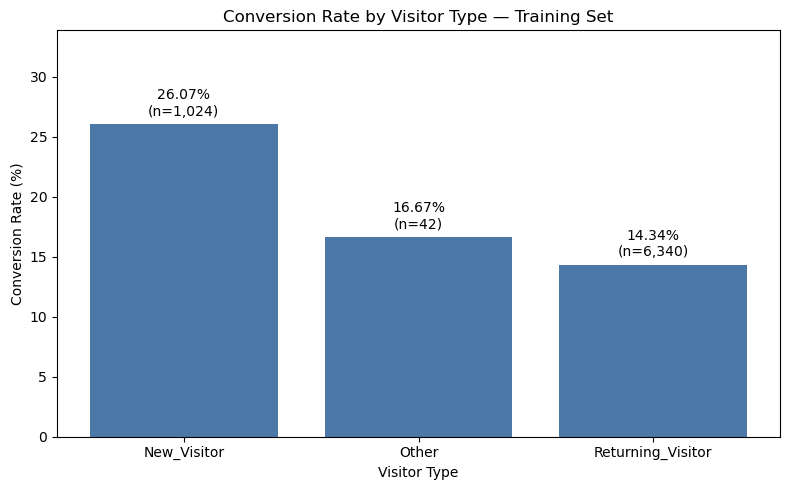

In [25]:
import matplotlib.pyplot as plt


# Mengurutkan kategori berdasarkan conversion rate.
plot_data = visitor_summary.sort_values(
    "conversion_rate_pct",
    ascending=False,
)

# Membuat grafik batang.
fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    plot_data.index,
    plot_data["conversion_rate_pct"],
    color="#4C78A8",
)

# Menambahkan persentase dan jumlah sesi pada setiap batang.
ax.bar_label(
    bars,
    labels=[
        f"{rate:.2f}%\n(n={count:,})"
        for rate, count in zip(
            plot_data["conversion_rate_pct"],
            plot_data["session_count"],
        )
    ],
    padding=4,
)

ax.set_title("Conversion Rate by Visitor Type — Training Set")
ax.set_xlabel("Visitor Type")
ax.set_ylabel("Conversion Rate (%)")

# Memberikan ruang untuk label di atas batang.
ax.set_ylim(0, plot_data["conversion_rate_pct"].max() * 1.3)

fig.tight_layout()
plt.show()

## Membandingkan konversi weekday dan weekend

In [26]:
# Menghitung jumlah sesi dan konversi berdasarkan Weekend.
weekend_summary = (
    eda_train.groupby("Weekend")["Revenue"]
    .agg(
        session_count="size",
        purchase_count="sum",
        conversion_rate_pct="mean",
    )
)

# Mengubah proporsi pembelian menjadi persentase.
weekend_summary["conversion_rate_pct"] = (
    weekend_summary["conversion_rate_pct"] * 100
).round(2)

# Memberikan label yang lebih mudah dibaca.
weekend_summary = weekend_summary.rename(
    index={
        False: "Weekday",
        True: "Weekend",
    }
)

weekend_summary

,session_count,purchase_count,conversion_rate_pct
Weekend,,,
Weekday,5669,869,15.33
Weekend,1737,314,18.08


## Membuat grafik konversi weekday dan weekend

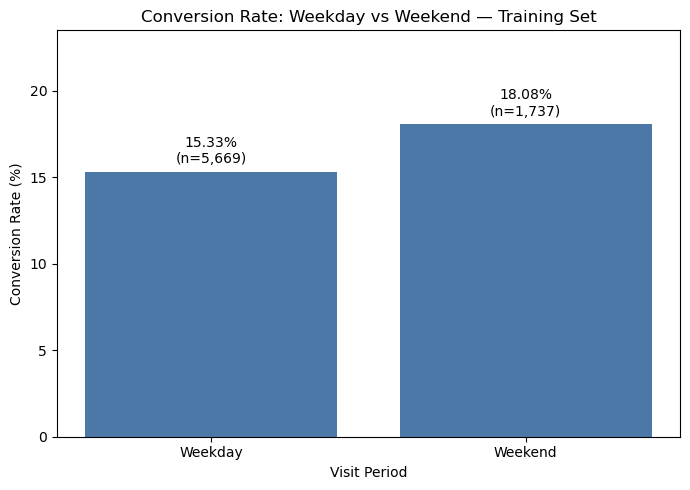

In [27]:
# Membuat grafik dari tabel ringkasan sebelumnya.
fig, ax = plt.subplots(figsize=(7, 5))

bars = ax.bar(
    weekend_summary.index,
    weekend_summary["conversion_rate_pct"],
    color="#4C78A8",
)

# Menampilkan persentase konversi dan jumlah sesi.
ax.bar_label(
    bars,
    labels=[
        f"{rate:.2f}%\n(n={count:,})"
        for rate, count in zip(
            weekend_summary["conversion_rate_pct"],
            weekend_summary["session_count"],
        )
    ],
    padding=4,
)

ax.set_title("Conversion Rate: Weekday vs Weekend — Training Set")
ax.set_xlabel("Visit Period")
ax.set_ylabel("Conversion Rate (%)")
ax.set_ylim(
    0,
    weekend_summary["conversion_rate_pct"].max() * 1.3,
)

fig.tight_layout()
plt.show()

## Conversion rate per bulan

In [28]:
# Menghitung jumlah sesi dan pembelian setiap bulan.
monthly_summary = (
    eda_train.groupby("Month")["Revenue"]
    .agg(
        session_count="size",
        purchase_count="sum",
        conversion_rate_pct="mean",
    )
)

# Mengubah proporsi pembelian menjadi persentase.
monthly_summary["conversion_rate_pct"] = (
    monthly_summary["conversion_rate_pct"] * 100
).round(2)

# Urutan kalender untuk bulan yang tersedia dalam dataset.
month_order = [
    "Feb", "Mar", "May", "June", "Jul",
    "Aug", "Sep", "Oct", "Nov", "Dec",
]

# Menampilkan bulan sesuai urutan kalender.
monthly_summary = monthly_summary.reindex(month_order)

monthly_summary

,session_count,purchase_count,conversion_rate_pct
Month,,,
Feb,111,3,2.70
Mar,1149,110,9.57
May,2021,231,11.43
June,169,18,10.65
Jul,254,41,16.14
Aug,269,48,17.84
Sep,275,53,19.27
Oct,338,79,23.37
Nov,1796,464,25.84


November memiliki conversion rate sekaligus jumlah pembelian tertinggi, sedangkan Mei memiliki jumlah sesi terbanyak pada training set.

## Membuat grafik conversion rate per bulan

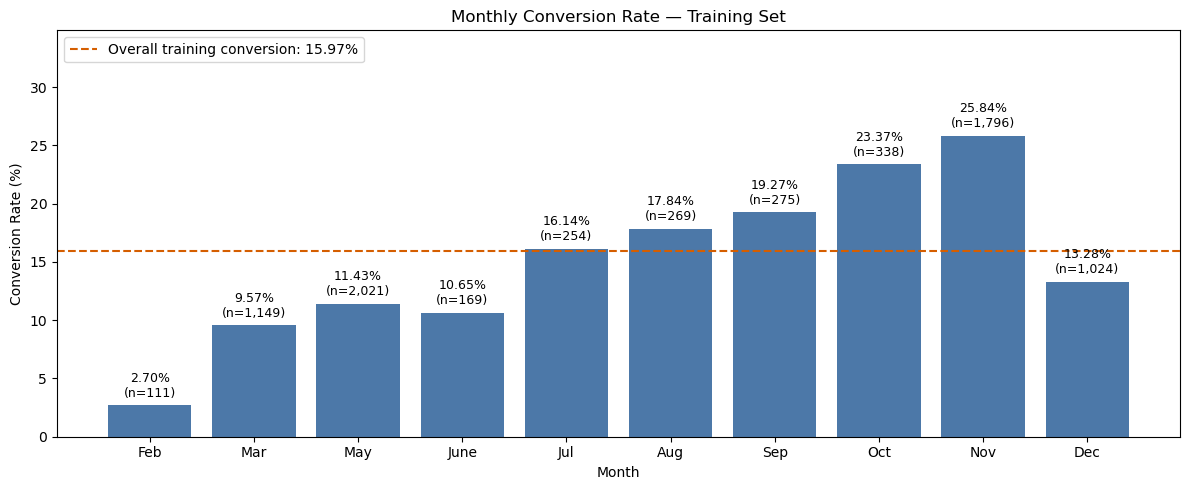

In [29]:
fig, ax = plt.subplots(figsize=(12, 5))

# Batang mengikuti urutan bulan pada monthly_summary.
bars = ax.bar(
    monthly_summary.index,
    monthly_summary["conversion_rate_pct"],
    color="#4C78A8",
)

# Label persentase konversi dan jumlah sesi.
ax.bar_label(
    bars,
    labels=[
        f"{rate:.2f}%\n(n={count:,})"
        for rate, count in zip(
            monthly_summary["conversion_rate_pct"],
            monthly_summary["session_count"],
        )
    ],
    padding=4,
    fontsize=9,
)

# Conversion rate seluruh sesi training.
overall_conversion = eda_train["Revenue"].mean() * 100

ax.axhline(
    y=overall_conversion,
    color="#D55E00",
    linestyle="--",
    label=f"Overall training conversion: {overall_conversion:.2f}%",
)

ax.set_title("Monthly Conversion Rate — Training Set")
ax.set_xlabel("Month")
ax.set_ylabel("Conversion Rate (%)")
ax.set_ylim(
    0,
    monthly_summary["conversion_rate_pct"].max() * 1.35,
)
ax.legend(loc="upper left")

fig.tight_layout()
plt.show()

## Aktivitas halaman produk berdasarkan pembelian

In [30]:
# Membandingkan aktivitas halaman produk berdasarkan hasil pembelian.
product_summary = (
    eda_train.groupby("Revenue")[
        [
            "ProductRelated",
            "ProductRelated_Duration",
        ]
    ]
    .agg(["median", "mean"])
    .rename(
        index={
            0: "Not Purchased",
            1: "Purchased",
        }
    )
    .round(2)
)

product_summary

ProductRelated        ProductRelated_Duration         
                      median   mean                  median     mean
Revenue                                                             
Not Purchased           16.0  28.19                  501.67  1053.36
Purchased               29.0  47.47                 1091.32  1834.79

## Membandingkan distribusi aktivitas halaman produk

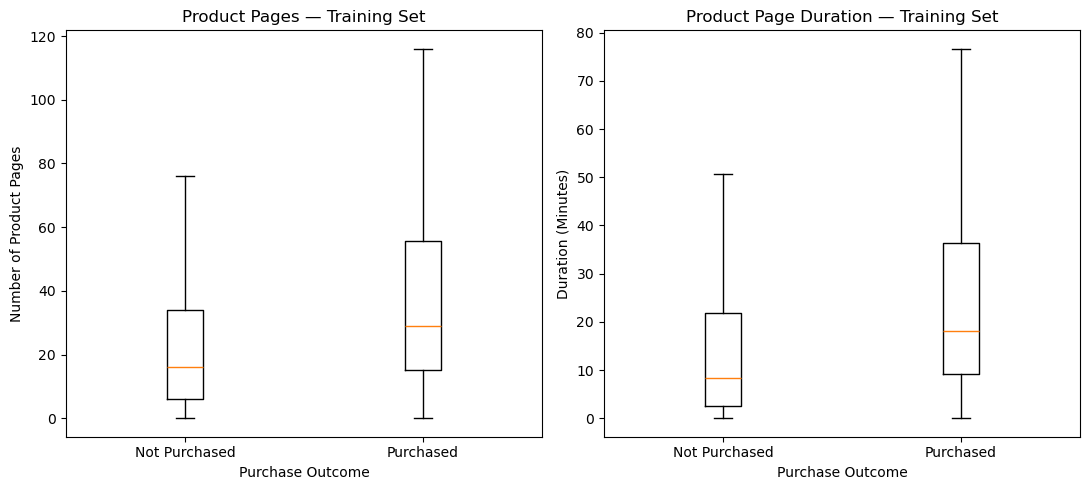

In [31]:
# Memisahkan sesi berdasarkan hasil pembelian.
not_purchased = eda_train[eda_train["Revenue"] == 0]
purchased = eda_train[eda_train["Revenue"] == 1]

fig, axes = plt.subplots(1, 2, figsize=(11, 5))

# Grafik jumlah halaman produk.
axes[0].boxplot(
    [
        not_purchased["ProductRelated"],
        purchased["ProductRelated"],
    ],
    showfliers=False,
)

axes[0].set_title("Product Pages — Training Set")
axes[0].set_ylabel("Number of Product Pages")

# Grafik durasi halaman produk, dikonversi ke menit.
axes[1].boxplot(
    [
        not_purchased["ProductRelated_Duration"] / 60,
        purchased["ProductRelated_Duration"] / 60,
    ],
    showfliers=False,
)

axes[1].set_title("Product Page Duration — Training Set")
axes[1].set_ylabel("Duration (Minutes)")

# Label untuk kedua grafik.
for ax in axes:
    ax.set_xticks([1, 2])
    ax.set_xticklabels(["Not Purchased", "Purchased"])
    ax.set_xlabel("Purchase Outcome")

fig.tight_layout()
plt.show()

Pada training set, sesi yang menghasilkan pembelian cenderung mengunjungi lebih banyak halaman produk dan menghabiskan waktu lebih lama. Median jumlah halaman mencapai 29 pada kelompok membeli, dibandingkan 16 pada kelompok tidak membeli, sedangkan median durasinya masing-masing sekitar 18,19 dan 8,36 menit. Namun, distribusi kedua kelompok masih tumpang tindih, sehingga jumlah halaman dan durasi saja belum cukup untuk membedakan hasil pembelian secara pasti.

## Membandingkan BounceRates dan ExitRates berdasarkan pembelian

In [32]:
# Membandingkan metrik bounce dan exit berdasarkan pembelian.
rate_summary = (
    eda_train.groupby("Revenue")[
        [
            "BounceRates",
            "ExitRates",
        ]
    ]
    .agg(["median", "mean"])
    .mul(100)
    .rename(
        index={
            0: "Not Purchased",
            1: "Purchased",
        }
    )
    .round(2)
)

rate_summary

BounceRates       ExitRates      
                   median  mean    median  mean
Revenue                                        
Not Purchased        0.43  2.56      2.86  4.76
Purchased            0.00  0.50      1.64  1.93

sesi yang membeli memiliki metrik bounce dan exit lebih rendah pada training set

## boxplot BounceRates dan ExitRates

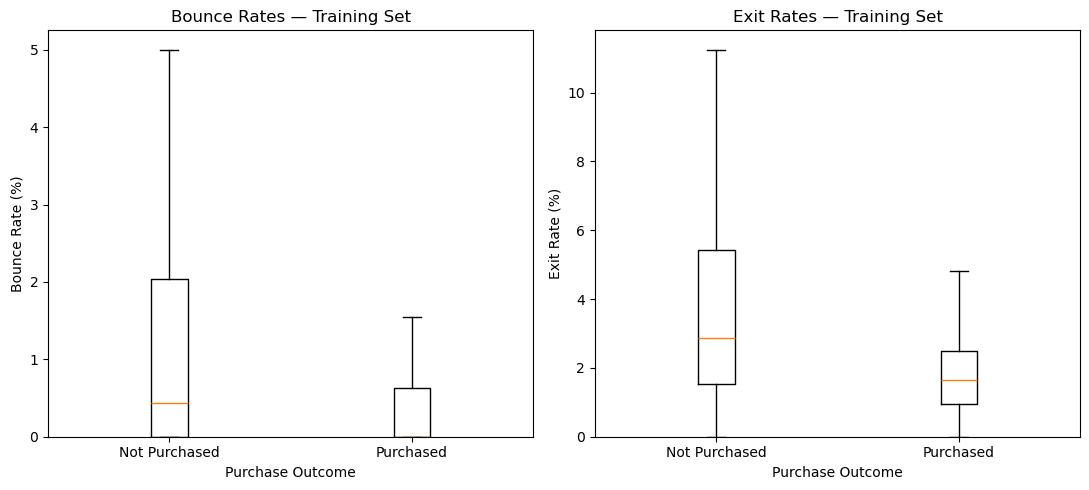

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5))

# Distribusi BounceRates dalam persen.
axes[0].boxplot(
    [
        not_purchased["BounceRates"] * 100,
        purchased["BounceRates"] * 100,
    ],
    showfliers=False,
)

axes[0].set_title("Bounce Rates — Training Set")
axes[0].set_ylabel("Bounce Rate (%)")

# Distribusi ExitRates dalam persen.
axes[1].boxplot(
    [
        not_purchased["ExitRates"] * 100,
        purchased["ExitRates"] * 100,
    ],
    showfliers=False,
)

axes[1].set_title("Exit Rates — Training Set")
axes[1].set_ylabel("Exit Rate (%)")

# Mengatur label kedua grafik.
for ax in axes:
    ax.set_xticks([1, 2])
    ax.set_xticklabels(["Not Purchased", "Purchased"])
    ax.set_xlabel("Purchase Outcome")
    ax.set_ylim(bottom=0)

fig.tight_layout()
plt.show()

BounceRates: kelompok membeli lebih terkonsentrasi pada nilai rendah. Mediannya mendekati nol. ExitRates: median kelompok membeli sekitar 1,64%, lebih rendah daripada kelompok tidak membeli yang sekitar 2,86%

## Memeriksa PageValues

In [34]:
pagevalue_summary = (
    eda_train.groupby("Revenue")["PageValues"]
    .agg(
        session_count="size",
        median="median",
        mean="mean",
        zero_pct=lambda values: values.eq(0).mean() * 100,
    )
    .rename(
        index={
            0: "Not Purchased",
            1: "Purchased",
        }
    )
    .round(2)
)

pagevalue_summary

,session_count,median,mean,zero_pct
Revenue,,,,
Not Purchased,6223,0.00,2.03,88.74
Purchased,1183,17.06,27.17,19.02


Pada kelompok tidak membeli, sekitar 89 dari setiap 100 sesi memiliki PageValues = 0. Karena nilai nol mendominasi, mediannya juga nol.
Pada kelompok membeli, hanya sekitar 19 dari setiap 100 sesi yang bernilai nol. Median dan rata-ratanya lebih tinggi, sehingga fitur ini menunjukkan hubungan yang kuat dengan hasil pembelian secara deskriptif.

## Visualisasi proporsi PageValues nol dan positif

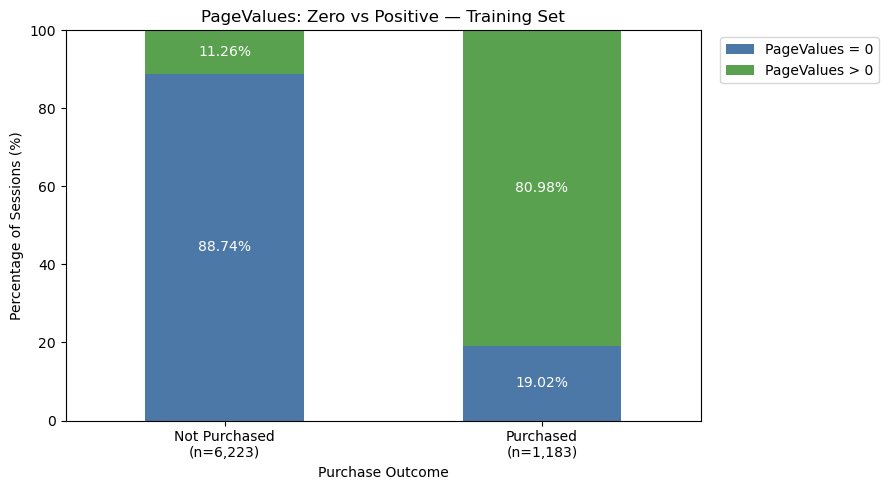

In [35]:
# Menyiapkan persentase nilai nol dan positif.
pagevalue_composition = pd.DataFrame(
    {
        "PageValues = 0": pagevalue_summary["zero_pct"],
        "PageValues > 0": 100 - pagevalue_summary["zero_pct"],
    }
)

# Membuat grafik batang bertumpuk.
ax = pagevalue_composition.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5),
    color=["#4C78A8", "#59A14F"],
    rot=0,
)

# Menampilkan persentase di dalam setiap bagian batang.
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.2f%%",
        label_type="center",
        color="white",
    )

# Menambahkan jumlah sesi pada label kelompok.
ax.set_xticklabels(
    [
        f"{label}\n(n={count:,})"
        for label, count in zip(
            pagevalue_summary.index,
            pagevalue_summary["session_count"],
        )
    ],
    rotation=0,
)

ax.set_title("PageValues: Zero vs Positive — Training Set")
ax.set_xlabel("Purchase Outcome")
ax.set_ylabel("Percentage of Sessions (%)")
ax.set_ylim(0, 100)
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1))

plt.tight_layout()
plt.show()

# Ringkasan hasil temuan Exploratory Data Analysis

Analisis menggunakan 7.406 sesi training dengan proporsi pembelian sebesar 15,97%.

- **Jenis pengunjung:** pengunjung baru memiliki conversion rate 26,07%, lebih tinggi daripada pengunjung yang kembali sebesar 14,34%. Namun, pengunjung yang kembali menghasilkan jumlah pembelian terbanyak.
- **Waktu kunjungan:** conversion rate weekend mencapai 18,08%, dibandingkan weekday sebesar 15,33%.
- **Bulan:** November memiliki conversion rate tertinggi, yaitu 25,84%. Mei memiliki jumlah sesi terbanyak, tetapi conversion rate-nya sebesar 11,43%.
- **Aktivitas produk:** sesi membeli memiliki median 29 halaman produk dan durasi 18,19 menit, dibandingkan 16 halaman dan 8,36 menit pada sesi tidak membeli. Distribusi kedua kelompok masih tumpang tindih.
- **Metrik halaman:** sesi membeli cenderung memiliki BounceRates dan ExitRates lebih rendah.
- **PageValues:** nilai nol ditemukan pada 88,74% sesi tidak membeli dan 19,02% sesi membeli. Perbedaan ini mendukung eksperimen model dengan dan tanpa PageValues untuk mengukur ketergantungan performanya.

Temuan ini bersifat deskriptif dan tidak membuktikan hubungan sebab-akibat. Kegunaan fitur untuk prediksi akan dinilai melalui pemodelan dan evaluasi. Validation dan test set tidak digunakan dalam eksplorasi hubungan fitur dengan pembelian ini.